In this notebook, I'll show you how to train a BPReveal model on ATAC-seq data.

If you already have a dataset you want to work with, you still have to go through the first section, since an important part of our pipeline involves shifting the ends of the reads.

## My workflow
I use the slurm module in BPReveal, which is designed to work on the cluster at Stowers. If you're at Stowers, you're in luck. If you're not at Stowers but use a slurm-based cluster, the files will probably need a bit of fiddling but should be useful. If you don't have a cluster, you need to run the commands yourself on the terminal. I've printed out all of the commands to run at the bottom of each cell.
(In this no-cluster case, you should remove the calls to jobsNonGpu and jobsGpu, and you can strike the jobSpecs stuff.)

In [19]:
# Boring setup stuff. You can change these directories to reflect your filesystem structure.
from bpreveal.tools.slurm import configSlurm, jobsNonGpu, writeDependencyScript, jobsGpu
import json
import matplotlib.pyplot as plt
import numpy as np
import pysam
import pybedtools
# The base directory is the root of this project. For this demo, I'm using a rondom
# scratch folder.
BASE_DIRECTORY="/n/projects/cm2363/bpreveal/test/atac-demo"
# The working directory is where all the files will be created. For this demo,
# I'm just using the base directory. The expectation is tha WORKING_DIRECTORY
# will have nothing in it at all when you start, and all of the files that get
# put there can be re-generated. BASE_DIRECTORY, on the other hand, might have
# valuable data (like jupyter notebooks, sequencing data, and so on.)
WORKING_DIRECTORY=BASE_DIRECTORY

# This is the directory where I have the atac_process_bam.r script.
SCRIPTS_DIRECTORY = "/n/projects/cm2363/bpreveal/doc/demos"

# If you're not using the slurm tools, you can skip this line.
# This sets up the required information to write slurm job scripts.
SLURM_CONFIG=configSlurm(["/home/cm2363/.zshrc"], "bpreveal-cerebro", WORKING_DIRECTORY)
for dirname in "sra,logs,slurm,fastq,json,pred,models,input,modisco,shap,bam,bedpe,bed,bw,fasta,h5,meme".split(","):
    !mkdir -p {WORKING_DIRECTORY}/{dirname}

# Preparing the data

In this section, I'll download and align some published ATAC-seq data. If you already have your own
data, you can substitute yours. Note that you must use the atac_process_bam R script to
generate your bigwigs.

In [2]:
# These are three ATAC-seq experiments done in fly embryos.
SRA_IDS = ["SRR22424124", "SRR22424119", "SRR22424118"]

In [3]:
# Download the SRA data.
jobSpecs = []
cmdsDownload = []
for srr in SRA_IDS:
    cmdsDownload.append("prefetch --progress --max-size 10t {sraId:s} -O {ddir:s}".format(sraId = srr, ddir=WORKING_DIRECTORY + "/sra"))
slurmNameDownload = jobsNonGpu(SLURM_CONFIG, cmdsDownload, "download", 5, 50, "1:00:00", extraHeader = "ml sratoolkit")
jobSpecs.append([slurmNameDownload, []])

In [4]:
# We will eventually need motif information for when we run MoDISco, so I'll go
# ahead and download that now. It won't be needed for a *long* time.
cmdsMeme = []
jasparAddress = "https://jaspar.uio.no/download/data/2024/CORE/JASPAR2024_CORE_insects_non-redundant_pfms_meme.txt"
cmdsMeme.append(f"wget -O{WORKING_DIRECTORY}/meme/jaspar_2024_insects.meme --no-check-certificate {jasparAddress}")
slurmNameMeme = jobsNonGpu(SLURM_CONFIG, cmdsMeme, "meme", 1, 1, "0:10:00")
jobSpecs.append([slurmNameMeme, []])


In [5]:
blacklistAddress = "https://github.com/Boyle-Lab/Blacklist/raw/refs/heads/master/lists/dm6-blacklist.v2.bed.gz"
cmdsBlacklist = [f"wget -O{WORKING_DIRECTORY}/bed/dm6.blacklist.bed.gz {blacklistAddress}"]
slurmNameBlacklistDownload = jobsNonGpu(SLURM_CONFIG, cmdsBlacklist, "blacklist", 1, 1, "0:10:00")
jobSpecs.append([slurmNameBlacklistDownload, []])
cmdsUnzipBlacklist = [f"gzip -d {WORKING_DIRECTORY}/bed/dm6.blacklist.bed.gz"]
slurmNameBlacklistUnzip = jobsNonGpu(SLURM_CONFIG, cmdsUnzipBlacklist, "blacklist-unzip", 1, 1, "0:10:00")
jobSpecs.append([slurmNameBlacklistUnzip, [slurmNameBlacklistDownload]])

In [6]:
# Now that the data are downloaded, turn the compressed files into fastq files that
# our aligner can process.
cmdsDump = []
for srr in SRA_IDS:
    cmdsDump.append(f"fasterq-dump {WORKING_DIRECTORY}/sra/{srr} -O {WORKING_DIRECTORY}/fastq --threads 70 --progress --mem 50000MB --bufsize 50000MB --curcache 50000MB")
slurmNameDump = jobsNonGpu(SLURM_CONFIG, cmdsDump, "dump", 70, 150, "1:00:00", extraHeader = "ml sratoolkit")
jobSpecs.append([slurmNameDump, [slurmNameDownload]])

In [7]:
# This is probably a line you can skip. This builds the bowtie indexes for SacCer3.
# You probably already have these files on your filesystem somewhere and you don't
# need to re-generate them. This also copies the whole genome into my working directory.
# For the 12 MB yeast genome, this isn't that bad, but please don't leave copies of
# multiple-gigabyte genomes lying around.
cmdGetGenome = f"""
cp /n/data1/genomes/indexes/dm6/dm6.fa {WORKING_DIRECTORY}/fasta
bowtie2-build --threads 50 {WORKING_DIRECTORY}/fasta/dm6.fa {WORKING_DIRECTORY}/fasta/dm6
cp /n/data1/genomes/indexs/dm6/extras/dm6.chrom.sizes {WORKING_DIRECTORY}/fasta
samtools faidx {WORKING_DIRECTORY}/fasta/dm6.fa --fai-idx {WORKING_DIRECTORY}/fasta/dm6.fa.fai
"""
slurmNameBuildGenome = jobsNonGpu(SLURM_CONFIG, [cmdGetGenome], "build-genome", 50, 50, "1:00:00", extraHeader = "ml bowtie2; ml samtools")
jobSpecs.append([slurmNameBuildGenome, []])

In [8]:
# Now align the data! I'm using bowtie2 here.
# If you don't have mbuffer, you can use the following invocation:
#f"""
#    bowtie2 -x {WORKING_DIRECTORY}/fasta/sacCer3 -p 65  \
#        -1 {WORKING_DIRECTORY}/fastq/{srr}_1.fastq \
#        -2 {WORKING_DIRECTORY}/fastq/{srr}_2.fastq \
#        --very-sensitive -X 1000 | \
#    samtools view -@5 -b -f 0x2 > {WORKING_DIRECTORY}/bam/{srr}.bam"""
# (The mbuffer tool shows you how much of a file has been consumed, it's handy for seeing
# how fast an aligner is working.)

cmdsAlign = []
for srr in SRA_IDS:
    cmdsAlign.append(f"""
    mbuffer -s1M -m1G -i {WORKING_DIRECTORY}/fastq/{srr}_1.fastq | \
    bowtie2 -x {WORKING_DIRECTORY}/fasta/dm6 -p 65 -1 - -2 {WORKING_DIRECTORY}/fastq/{srr}_2.fastq --very-sensitive -X 1000 | \
    samtools view -@5 -b -f 0x2 > {WORKING_DIRECTORY}/bam/{srr}.bam""")
slurmNameAlign = jobsNonGpu(SLURM_CONFIG, cmdsAlign, "align", 70, 100, "1:00:00", extraHeader = "ml bowtie2\nml samtools")
jobSpecs.append([slurmNameAlign, [slurmNameBuildGenome, slurmNameDump]])

In [9]:
# Next, I'll use picard to mark duplicate before creating the bigwig. 
cmdsSort = []
for srr in SRA_IDS:
    cmdsSort.append(f"""
    samtools sort -@ 30 -o {WORKING_DIRECTORY}/bam/{srr}.sort.bam {WORKING_DIRECTORY}/bam/{srr}.bam"""
    )
slurmNameSort = jobsNonGpu(SLURM_CONFIG, cmdsSort, "sortBam", 30, 100, "1:00:00", extraHeader = "ml samtools")
jobSpecs.append([slurmNameSort, [slurmNameAlign]])

In [10]:
# Next, I'll use picard to mark duplicate before creating the bigwig. 
cmdsMarkDups = []
for srr in SRA_IDS:
    cmdsMarkDups.append(f"""
    picard MarkDuplicates I={WORKING_DIRECTORY}/bam/{srr}.sort.bam \
                          O={WORKING_DIRECTORY}/bam/{srr}.dup.bam \
                          M={WORKING_DIRECTORY}/bam/{srr}.dup.txt \
                          ASSUME_SORT_ORDER=coordinate"""
    )
slurmNameMarkDups = jobsNonGpu(SLURM_CONFIG, cmdsMarkDups, "markDups", 2, 100, "1:00:00", extraHeader = "ml picard")
jobSpecs.append([slurmNameMarkDups, [slurmNameSort]])

In [11]:
# The next step is a quick one - I need to index the picard-generated bam files.
cmdsIndexBam = []
for srr in SRA_IDS:
    cmdsIndexBam.append(f"""
    samtools index {WORKING_DIRECTORY}/bam/{srr}.dup.bam
    """)
slurmNameIndexBam = jobsNonGpu(SLURM_CONFIG, cmdsIndexBam, "indexBam", 2, 100, "1:00:00", extraHeader = "ml samtools")
jobSpecs.append([slurmNameIndexBam, [slurmNameMarkDups]])

In [12]:
# Now we use the lab's atac processing script to convert the raw bam files into usable bigwigs.
# You may need to install some R packages to get this to work.
cmdsProcBam = []
for srr in SRA_IDS:
    cmdsProcBam.append(f"""
    Rscript {SCRIPTS_DIRECTORY}/atac_process_bam.r \
        --file {WORKING_DIRECTORY}/bam/{srr}.dup.bam \
        --bigwig_file_name_output {WORKING_DIRECTORY}/bw/{srr}.bw \
        --deduplicate_file T --tn5_cut_correction T \
        --minimum_fragment_size 10 --maximum_fragment_size 600 \
        --cut_site_export T
    """)
slurmNameProcBam = jobsNonGpu(SLURM_CONFIG, cmdsProcBam, "procBam", 2, 100, "1:00:00", extraHeader = "ml zeitlinger\nml samtools")
jobSpecs.append([slurmNameProcBam, [slurmNameIndexBam]])

In [13]:
# Now that we have coverage, we can call peaks. I'll use macs2.

cmdsCallPeaks = []
bamFiles = [f"{WORKING_DIRECTORY}/bam/{srr}.dup.bam" for srr in SRA_IDS]
bamFileStr = " ".join(bamFiles)
cmdsCallPeaks.append(f"""
    macs2 callpeak -f BAMPE --nomodel -t {bamFileStr} --outdir {WORKING_DIRECTORY}/bed -n macs
    """)

slurmNameCallPeaks = jobsNonGpu(SLURM_CONFIG, cmdsCallPeaks, "callPeaks", 1, 50, "1:00:00", extraHeader = "ml macs2")
jobSpecs.append([slurmNameCallPeaks, [slurmNameAlign]])

In [14]:
cmdsMergeBigwigs = []
bwFiles = []
for srr in SRA_IDS:
    bwFiles.append(f"{WORKING_DIRECTORY}/bw/{srr}.bw")

outBw = f"{WORKING_DIRECTORY}/bw/merged.bw"
sizes = f"{WORKING_DIRECTORY}/fasta/dm6.chrom.sizes"
inFiles = " ".join(bwFiles)
cmdsMergeBigwigs.append(f"""
    {SCRIPTS_DIRECTORY}/mergeBigWig.py --chrom-sizes {sizes} --output {outBw} {inFiles}
    """)
slurmNameMergeBigwigs = jobsNonGpu(SLURM_CONFIG, cmdsMergeBigwigs, "mergeBigwigs", 1, 10, "0:10:00")
jobSpecs.append([slurmNameMergeBigwigs, [slurmNameProcBam]])

In [9]:
writeDependencyScript(SLURM_CONFIG, jobSpecs, "getData", cancelScript = WORKING_DIRECTORY + "/slurm/cancel_getData.zsh")

## Review
In this section, we got the sequencing data and aligned it. This gave us
bam files. We then called peaks using MACS2 and refined those peaks with IDR.
If you have another peak caller that you like, or a different aligner, you can use that instead.

We then used a custom R script to process the bam files to generate bigwigs. The generated bigwigs represent the cutsites where the Tn5 enzyme cleaved the DNA, not the
total fragment pileup.

We merged the bigwigs from the replicates, and we'll use that merged bigwig for training.

The following files will be necessary later on:
* bw/merged.bw
    * The cutsite data. This is what we'll train on, and we'll benchmark our model's performance against this data.
* bed/all.narrowPeak
    * All possible peaks from all the replicates, with no filtering. When we select regions to train our bias model, we'll be sure to exclude these regions.
* bed/idr.narrowPeak
    * A high-confidence set of peaks that we'll use to train our main model.
* bed/tile_bias.bed
    * A set of background regions that we'll use to train the bias model.
* meme/jaspar_2024_insects.meme
    * A curated set of motifs for insects. We'll use this *way* down the line, when we get to motif identification.
* fasta/dm6.fa
    * The fly genome.
* fasta/dm6.fa.fai
    * An index file that is needed to load sequences out of dm6.fa with pysam.
* fasta/dm6.chrom.sizes
    * A file containing the sizes of the chromosomes in dm6. Used mostly to generate bigwigs.


# Preparing data for BPReveal

(You should run the steps above before progressing to this part.)

Now that we have called peaks and data, we can go ahead and get those data in a format that BPReveal will need.
We also need to choose architectural parameters for the model.

In [377]:
# A few constants that are useful.
GENOME_FASTA = f"{WORKING_DIRECTORY}/fasta/dm6.fa"
BW_FILE = f"{WORKING_DIRECTORY}/bw/merged.bw"
PEAKS_BED = f"{WORKING_DIRECTORY}/bed/macs_peaks.narrowPeak"

In [22]:
# I'm going to use a fixed train/test/validation split.
TEST_CHROMS = ["chrX"]
VAL_CHROMS = ["chr2L"]
TRAIN_CHROMS = ["chr3L", "chr3R", "chr2R"]

# This is an architecture that works well for atac-seq data.
OUTPUT_LENGTH=1000
NUM_LAYERS = 8
CONV1_KERNEL_SIZE = 21
PROFILE_KERNEL_SIZE=75
NUM_FILTERS = 64

# Now, I need to determine the input size for the model.
# There is a script in BPReveal called lengthCalc that will do this for us.

input_length_str = !lengthCalc --output-len {OUTPUT_LENGTH} \
                                            --n-dil-layers {NUM_LAYERS} \
                                            --conv1-kernel-size {CONV1_KERNEL_SIZE} \
                                            --profile-kernel-size {PROFILE_KERNEL_SIZE}
INPUT_LENGTH=int(input_length_str[0])
# Receptive field represents how many input bases each output considers in making
# its prediction.
RECEPTIVE_FIELD=INPUT_LENGTH - OUTPUT_LENGTH+1
# During training, we jitter the samples around a bit as a form of augmentation.
# You can probably leave this at 100.
MAX_JITTER = 100
# Padding is the number of bases on each side of the input that do not have
# corresponding predictions. 
PADDING = (RECEPTIVE_FIELD - 1)//2


In [56]:
jobSpecs = []

In [57]:
def generateGenomeTiles():
    allowChroms = [" --allow-chrom " + x for x in TRAIN_CHROMS + VAL_CHROMS + TEST_CHROMS]
    allowChroms = "".join(allowChroms)
    tileBedFname = f"{WORKING_DIRECTORY}/bed/tile_all.bed"
    # Note that I'm not using the IDR peaks as my blacklist. Instead I'm using
    # every single peak that was called from any of the replicates.
    tileCmd = f"""tileGenome --genome {GENOME_FASTA} --output-length {OUTPUT_LENGTH} \
        --input-length {INPUT_LENGTH} --spacing 0 --chrom-edge-boundary {INPUT_LENGTH} \
        {allowChroms}\
        --output-bed {tileBedFname} --verbose"""
    nameTile = jobsNonGpu(SLURM_CONFIG, [tileCmd], "tileGenome", 10, 40, "1:00:00")
    return nameTile
slurmNameGenomeTile = generateGenomeTiles()
jobSpecs.append([slurmNameGenomeTile, []])

In [58]:
# Last, I need a set of regions that are *not* in atac-seq peaks.
# I'm going to do this by tiling the genome and then removing any
# tiles that overlap with a called peak.
def generateBackgroundTiles():
    allowChroms = [" --allow-chrom " + x for x in TRAIN_CHROMS + VAL_CHROMS + TEST_CHROMS]
    allowChroms = "".join(allowChroms)
    tileBedFname = f"{WORKING_DIRECTORY}/bed/tile_bias.bed"
    # I'm using every single peak that was called from any of the replicates.
    tileCmd = f"""tileGenome --genome {GENOME_FASTA} --output-length {OUTPUT_LENGTH} \
        --input-length {INPUT_LENGTH} --spacing 2000 --chrom-edge-boundary {INPUT_LENGTH} \
        --blacklist {WORKING_DIRECTORY}/bed/macs_peaks.narrowPeak {allowChroms}\
        --output-bed {tileBedFname} --verbose"""
    nameTile = jobsNonGpu(SLURM_CONFIG, [tileCmd], "tileBias", 10, 40, "1:00:00")
    return nameTile
slurmNameBackgroundTile = generateBackgroundTiles()
jobSpecs.append([slurmNameBackgroundTile, []])

# This will generate a file called tile_bias.bed
# that contains many (~16k) regions over the genome that could be used
# to train the bias model. In the next step, we'll refine these regions.

Here are the bed files we have so far, along with the merged coverage:
![peaks](atac_peaks.png)

The three SRR*.narrowPeak tracks are the peak calls for the three replicates, the idr.narrowPeak file is the refined peak set that we'll train on, and tile_bias.bed is the set of regions that we'll use to train the bias model.

In [59]:
def generateNegativeSet():
    # We want to include some nonpeak regions in our training data,
    # maybe about 20 percent.
    # This function reads in the IDR peaks and saves them to modelRegions.narrowPeak
    # it then selects 1/10 the number of IDR peaks from one of the MACS2 peak calls
    # and another 1/10 of the number of IDR peaks from the background regions.
    # In total, we'll have 80% IDR peaks, 10 % crummy peaks, and 10 % background.
    rng = 0
    blackRegions = []
    with open(f"{WORKING_DIRECTORY}/bed/dm6.blacklist.bed", "r") as inBlacklist:
        for line in inBlacklist:
            lsp = line.split()
            chrom = lsp[0]
            start = int(lsp[1])
            end = int(lsp[2])
            blackRegions.append((chrom, start, end))
    with open(f"{WORKING_DIRECTORY}/bed/modelRegions.bed", "w") as outFp, \
         open(f"{WORKING_DIRECTORY}/bed/macs_peaks.narrowPeak", "r") as inPeaks:
        for line in inPeaks:
            lsp = line.split()
            chrom, start, end = lsp[:3]
            start = int(start)
            end = int(end)
            skip = False
            for bc, bs, be in blackRegions:
                if chrom == bc and start < be and end > bs:
                    skip = True
                    break
            if skip:
                continue
            peakPos = int(lsp[9])
            center = int(start) + peakPos
            outFp.write(f"{chrom}\t{center}\t{center+1}\n")
generateNegativeSet()

In [60]:
# Now it's time to generate the bed files that will actually be used to train.
def prepareBed():
    # For the peaks we're going to train on, we'll use all of the peaks that
    # were selected above. Hence max-quantile is 1 and min-counts is 1.
    headSpecPeaks = [{"bigwig-names" : [BW_FILE], "max-quantile" : 1,
                     "min-quantile" : 0.001, "negative-set-quantile": 0.5,
                     "negative-set-include-fraction": 0.1}]
    headSpecBias  = [{"bigwig-names" : [BW_FILE], "max-quantile" : 0.7,
                     "min-quantile" : 0.01}]
    # For the bias model, I'm going to lower max-quantile to 0.7.
    # This will reject the highest half of the background regions we made
    # in generateBackgroundTiles.

    prepareBedPeaksConfig = {
        "heads" : headSpecPeaks, 
        "splits" : {"test-chroms"  : TEST_CHROMS, 
                    "val-chroms"   : VAL_CHROMS,
                    "train-chroms" : TRAIN_CHROMS,
                    "regions" : [f"{WORKING_DIRECTORY}/bed/modelRegions.bed"]},
        "genome" : GENOME_FASTA,
        "output-length" : OUTPUT_LENGTH,
        "input-length" : INPUT_LENGTH,
        "max-jitter" : MAX_JITTER,
        "output-prefix" : WORKING_DIRECTORY + "/bed/peak", 
        "resize-mode" : "center", 
        "remove-overlaps" : True,
        "overlap-max-distance" : 100,
        "num-threads" : 10,
        "verbosity" : "INFO"}
    with open(WORKING_DIRECTORY + "/json/prepareBedPeaks.json", "w") as fp:
        json.dump(prepareBedPeaksConfig, fp, indent=4)

    prepareBedNonpeaksConfig = {
        "heads" : headSpecBias, 
        "splits" : {"test-chroms"  : TEST_CHROMS, 
                    "val-chroms"   : VAL_CHROMS,
                    "train-chroms" : TRAIN_CHROMS,
                    "regions" : [f"{WORKING_DIRECTORY}/bed/tile_bias.bed"]},
        "genome" : GENOME_FASTA,
        "output-length" : OUTPUT_LENGTH,
        "input-length" : INPUT_LENGTH,
        "max-jitter" : MAX_JITTER,
        "output-prefix" : WORKING_DIRECTORY + "/bed/nonpeak", 
        "resize-mode" : "center", 
        "remove-overlaps" : True,
        "overlap-max-distance" : 100,
        "num-threads" : 10,
        "verbosity" : "INFO"}
    with open(WORKING_DIRECTORY + "/json/prepareBedNonpeaks.json", "w") as fp:
        json.dump(prepareBedNonpeaksConfig, fp, indent=4)

    namePrepareBed = jobsNonGpu(SLURM_CONFIG,
        ["prepareBed " + WORKING_DIRECTORY + "/json/prepareBedPeaks.json",
         "prepareBed " + WORKING_DIRECTORY + "/json/prepareBedNonpeaks.json"],
        "preparePeaks", 10, 40, "1:00:00")
    return namePrepareBed

slurmNamePrepareBed = prepareBed()
jobSpecs.append([slurmNamePrepareBed, [slurmNameBackgroundTile, slurmNameGenomeTile]])

In [61]:
# Now that we have our regions for training, validation, and testing,
# we can go ahead and build the data files for training.
# The training scripts use a custom HDF5 file to hold the training data.
# While this means we can't just feed in a bed and bigwig, it allows us to use
# all sorts of unusual data types with the training scripts, such as reads
# that don't lie on a chromosome.

def prepareTrainingData():
    configFnames = []
    for split in ["train", "val"]:
        for dataset in ["peak", "nonpeak"]:
            heads = []
            heads.append({
                "revcomp-task-order" : "auto",
                "bigwig-files" : [BW_FILE]})
            config = {"genome" : GENOME_FASTA, 
                      "input-length" : INPUT_LENGTH,
                      "output-length" : OUTPUT_LENGTH,
                      "max-jitter" : MAX_JITTER,
                      "regions" : WORKING_DIRECTORY + "/bed/" + dataset + "_" + split + ".bed",
                      "output-h5" : WORKING_DIRECTORY + "/input/" + dataset + "_" + split + ".h5",
                      "reverse-complement" : True,
                      "heads" : heads,
                      "verbosity" : "DEBUG"}
            configFname =WORKING_DIRECTORY + "/json/prepareInput" + dataset + "_" + split+ ".json" 
            with open(configFname, "w") as fp:
                json.dump(config, fp, indent=2)
            configFnames.append(configFname)
    namePrepareData = jobsNonGpu(SLURM_CONFIG, ["prepareTrainingData {0:s}".format(configFname) 
                    for configFname in configFnames], 
                "prepareTrainingData", 2, 20, "1:00:00")
    return namePrepareData
namePrepareData = prepareTrainingData()
jobSpecs.append([namePrepareData, [slurmNamePrepareBed]])

In [62]:
writeDependencyScript(SLURM_CONFIG, jobSpecs, "prepareData",
                      cancelScript = WORKING_DIRECTORY + "/slurm/cancel_prepareData.zsh")

## Files generated so far
Let's review what we've made.

* bed/tile_bias.bed
    * A set of regions across the genome that do not intersect with a possible peak. We'll select some of these regions to train our bias model.
* bed/peak_*.bed
    * These bed files contain high-quality peaks that we can use to train the main model.
* bed/nonpeak_*.bed
    * These contain regions selected from tile_bias.bed that we'll use to train the bias model.
 
The files in the bed directory are divided by split.
* bed/*_train.bed
    * Regions that will be used to train the model.
* bed/*_val.bed
    * Regions that we will use to measure the model's performance during training.
* bed/*_test.bed
    * Regions that will never be used during training. We'll check the model's performance on these regions.
* bed/*_all.bed
    * A concatenation of the training, validation, and test sets. When we want to make predictions on all regions, we'll use this bed file.
* bed/*_reject.bed
    * Regions that failed the checks in prepareBed. These may have N nucleotides, or be at the edge of a chromosome, or have too few counts, or some other issue.
 
We then combined the bigwig and bed files into input files that will be fed to the models during training.

* input/peak_train.h5
    * The training examples for the main model.
* input/peak_val.h5
    * Validation examples for the main model.
* input/nonpeak_train.h5
    * Nonpeak training examples.
* input/nonpeak_val.h5
    * Nonpeak validation regions. 

In [63]:
# Let's take a look at some of the files we've generated.
def checkBed(bedFname):
    print(f"Analyzing bed file {bedFname}")
    chromCounts = {}
    numLines = 0
    with open(bedFname, "r") as fp:
        for line in fp:
            lsp = line.split()
            chrom = lsp[0]
            if chrom not in chromCounts:
                chromCounts[chrom] = 0
            chromCounts[chrom] += 1
            numLines += 1
    chromCountAr = [(x[0], x[1]) for x in chromCounts.items()]
    chromCountAr = sorted(chromCountAr, key=lambda x: -x[1])
    print(f"{numLines=}")
    print(f"Chromosome counts: {chromCountAr[:5]}")

checkBed(f"{WORKING_DIRECTORY}/bed/modelRegions.bed")
checkBed(f"{WORKING_DIRECTORY}/bed/peak_train.bed")
checkBed(f"{WORKING_DIRECTORY}/bed/peak_test.bed")
checkBed(f"{WORKING_DIRECTORY}/bed/peak_val.bed")
checkBed(f"{WORKING_DIRECTORY}/bed/peak_all.bed")
checkBed(f"{WORKING_DIRECTORY}/bed/nonpeak_all.bed")

Analyzing bed file /n/projects/cm2363/bpreveal/test/atac-demo/bed/modelRegions.bed
numLines=60796
Chromosome counts: [('chr3R', 13808), ('chr3L', 12080), ('chr2R', 10866), ('chr2L', 10050), ('chrX', 9246)]
Analyzing bed file /n/projects/cm2363/bpreveal/test/atac-demo/bed/peak_train.bed
numLines=20134
Chromosome counts: [('chr3R', 7315), ('chr2R', 6470), ('chr3L', 6349)]
Analyzing bed file /n/projects/cm2363/bpreveal/test/atac-demo/bed/peak_test.bed
numLines=5070
Chromosome counts: [('chrX', 5070)]
Analyzing bed file /n/projects/cm2363/bpreveal/test/atac-demo/bed/peak_val.bed
numLines=5570
Chromosome counts: [('chr2L', 5570)]
Analyzing bed file /n/projects/cm2363/bpreveal/test/atac-demo/bed/peak_all.bed
numLines=30774
Chromosome counts: [('chr3R', 7315), ('chr2R', 6470), ('chr3L', 6349), ('chr2L', 5570), ('chrX', 5070)]
Analyzing bed file /n/projects/cm2363/bpreveal/test/atac-demo/bed/nonpeak_all.bed
numLines=14086
Chromosome counts: [('chr3R', 3306), ('chr3L', 3131), ('chrX', 2769), ('

It looks like our bed files are split up nicely, with the training bed having three chromosomes worth of regions and the other two splits having one chromosome each.

In [64]:
! h5dump -H {WORKING_DIRECTORY}/input/peak_train.h5

HDF5 "/n/projects/cm2363/bpreveal/test/atac-demo/input/peak_train.h5" {
GROUP "/" {
   DATASET "head_0" {
      DATATYPE  H5T_IEEE_F32LE
      DATASPACE  SIMPLE { ( 40268, 1200, 1 ) / ( 40268, 1200, 1 ) }
   }
   GROUP "metadata" {
      ATTRIBUTE "bpreveal_version" {
         DATATYPE  H5T_STRING {
            STRSIZE H5T_VARIABLE;
            STRPAD H5T_STR_NULLTERM;
            CSET H5T_CSET_UTF8;
            CTYPE H5T_C_S1;
         }
         DATASPACE  SCALAR
      }
      ATTRIBUTE "config" {
         DATATYPE  H5T_STRING {
            STRSIZE H5T_VARIABLE;
            STRPAD H5T_STR_NULLTERM;
            CSET H5T_CSET_UTF8;
            CTYPE H5T_C_S1;
         }
         DATASPACE  SCALAR
      }
      ATTRIBUTE "created_date" {
         DATATYPE  H5T_STRING {
            STRSIZE H5T_VARIABLE;
            STRPAD H5T_STR_NULLTERM;
            CSET H5T_CSET_UTF8;
            CTYPE H5T_C_S1;
         }
         DATASPACE  SCALAR
      }
   }
   DATASET "sequence" {
      DATATYPE 

We can see the sequence and head_0 groups. Note that the model input length is 2114 and the output length is 1000, but this file contains 2314 bp of input and 1200 bp of output. This is because we'll be jittering our input windows by +/- 100 bp during training, and so we need that extra information.

# Training the models

In [65]:
jobSpecs = []

In [66]:
# First, we need to train up the bias model.
def trainBias():
    heads = [{"num-tasks" : 1,
                  "profile-loss-weight" : 1, 
                  "head-name" : "bias",
                  "counts-loss-frac-target" : 0.1}]

    
    #And now the whole config file:
    biasTrainConfig = {
        "settings" : {
            "output-prefix" : WORKING_DIRECTORY + "/models/bias", 
            "epochs" : 200,
            "max-jitter" : 100,
            "early-stopping-patience" : 20,
            "batch-size" : 128,
            "learning-rate" : 0.004,
            "learning-rate-plateau-patience" : 5,
            "architecture" : {
                "architecture-name" : "bpnet", 
                "input-length" : INPUT_LENGTH,
                "output-length" : OUTPUT_LENGTH,
                "model-name" : "bias",
                "model-args" : "",
                "filters" : NUM_FILTERS,
                "layers" : NUM_LAYERS,
                "input-filter-width" : CONV1_KERNEL_SIZE,
                "output-filter-width" : PROFILE_KERNEL_SIZE
            }
        },
        "train-data" : WORKING_DIRECTORY + "/input/nonpeak_train.h5",
        "val-data" : WORKING_DIRECTORY + "/input/nonpeak_val.h5",
        "heads" : heads,
        "verbosity" : "DEBUG"
    }
    jsonFname = f"{WORKING_DIRECTORY}/json/trainBias.json"
    with open(jsonFname, "w") as fp:
        json.dump(biasTrainConfig, fp, indent=4)
    nameTrainBias = jobsGpu(SLURM_CONFIG, [f"trainSoloModel {jsonFname}"], "trainBias", 10, 50, "5:00:00")
    return nameTrainBias
nameTrainBias = trainBias()
jobSpecs.append([nameTrainBias, []])

In [67]:
# Once the bias model is trained, we should make predictions and also check its loss curve.
def lossPlot(model):
    cmdLoss = f"""makeLossPlots --json {WORKING_DIRECTORY}/models/{model}.history.json --output {WORKING_DIRECTORY}/models/{model}.png"""
    nameLoss = jobsNonGpu(SLURM_CONFIG, [cmdLoss], f"makeLossPlots_{model}", 1, 1, "1:00")
    return nameLoss
nameLossBias = lossPlot("bias")
jobSpecs.append([nameLossBias, [nameTrainBias]])

In [68]:
# Here's how I make predictions:
def predict(modelFname, outName):
    predictConfig = {
        "settings" : {
            "output-h5" : f"{WORKING_DIRECTORY}/pred/{outName}.h5", 
            "batch-size" : 128,
            "heads" : 1,
            
            "architecture" : {
                "model-file" : f"{WORKING_DIRECTORY}/models/{modelFname}.keras",
                "input-length" : INPUT_LENGTH,
                "output-length" : OUTPUT_LENGTH
            }
        },
        "bed-file" : WORKING_DIRECTORY + "/bed/tile_all.bed",
        "genome" : GENOME_FASTA, 
        "verbosity" : "DEBUG"
    }
    
    jsonFname = f"{WORKING_DIRECTORY}/json/predict{outName}.json"
    with open(jsonFname, "w") as fp:
        json.dump(predictConfig, fp)
    namePredict = jobsGpu(SLURM_CONFIG, [f"makePredictions {jsonFname}"],
                              f"predict{outName}", 5, 10, "1:00:00")
    return namePredict
namePredictBias = predict("bias", "bias")
jobSpecs.append([namePredictBias, [nameTrainBias]])

In [69]:
# The prediction step generates an hdf5 file of the model's output, so we need to
# convert that to a bigwig to see it.
def predToBw(fname):
    predCmd = "predictToBigwig " +\
          "--h5 {wd:s}/pred/{fn:s}.h5 " +\
          "--bw {wd:s}/pred/{fn:s}.bw "+\
          "--head-id 0 --task-id 0 --mode profile "+\
          "--threads 20 --verbose"

    nameBw = jobsNonGpu(SLURM_CONFIG, [predCmd.format(wd=WORKING_DIRECTORY, fn=fname)], 
               f"predToBigwig{fname}", 20, 20, "1:00:00")
    return nameBw
nameBwBias = predToBw("bias")
jobSpecs.append([nameBwBias, [namePredictBias]])

In [70]:
# Now that we have a bias model in hand, we need to train the transformation and combined models.
# For this demonstration, the transformation model probably isn't necessary since the bias model
# was trained on the exact same dataset I'm going to use for the combined model. 
# I'll still go through training a transformation model since it may be needed if your bias model
# comes from a different experiment. 
def trainTransformation():
    heads = [{"num-tasks" : 1, 
              "profile-loss-weight" : 1, 
              "head-name" : "atac",
              "counts-loss-weight" : 10}]
    
    transformationTrainConfig = {
        "settings" : {
            "output-prefix" : WORKING_DIRECTORY + "/models/transformation", 
            "epochs" : 200,
            "early-stopping-patience" : 5,
            "batch-size" : 128,
            "learning-rate" : 0.04, #Note the very aggressive LR; we can do this because there are so few parameters. 
            "learning-rate-plateau-patience" : 3,
            "solo-model-file" : WORKING_DIRECTORY + "/models/bias.keras",
            "input-length" : INPUT_LENGTH, 
            "output-length" : OUTPUT_LENGTH,
            "max-jitter" : 100,
            "profile-architecture" : {
                "name" : "simple", 
                "types" : ["linear", "sigmoid"]},
            "counts-architecture" : {
                "name" : "simple", 
                "types" : ["linear", "sigmoid"]}},
            
        "train-data" : WORKING_DIRECTORY+ "/input/peak_train.h5",
        "val-data" : WORKING_DIRECTORY + "/input/peak_val.h5",
        "heads" : heads,
        "verbosity" : "INFO"
    }
    jsonFname = WORKING_DIRECTORY + "/json/trainTransformation.json"
    
    with open(jsonFname, "w") as fp:
        json.dump(transformationTrainConfig, fp)
    nameTrainTransformation = jobsGpu(SLURM_CONFIG, [f"trainTransformationModel {jsonFname}"],
                                      "trainTransformation", 10, 20, "2:00:00")
    return nameTrainTransformation
nameTrainTransformation = trainTransformation()
jobSpecs.append([nameTrainTransformation, [nameTrainBias]])
# I'm not going to bother with making predictions from the transformation model since they'll be
# essentially identical to the ones from the bias model.

In [71]:
namePredictTransformation = predict("transformation", "transformation")
jobSpecs.append([namePredictTransformation, [nameTrainTransformation]])
nameBwTransformation = predToBw("transformation")
jobSpecs.append([nameBwTransformation, [namePredictTransformation]])

In [72]:
# Now for the big one. Time to train the combined model. 
def trainCombined():
    heads = [{"num-tasks" : 1, 
              "profile-loss-weight" : 1, 
              "head-name" : "atac",
              "counts-loss-weight": 400, 
              "counts-loss-frac-target" : 0.1,
              "use-bias-counts" : False}]
    
    
    #And now the whole config file:
    combinedTrainConfig = {
        "settings" : {
            "output-prefix" : WORKING_DIRECTORY + "/models/joint", 
            "epochs" : 200,
            "early-stopping-patience" : 20,
            "batch-size" : 64,
            "learning-rate" : 0.004,
            "learning-rate-plateau-patience" : 5,
            "max-jitter" : 100,
            "transformation-model" : {
                "transformation-model-file" : WORKING_DIRECTORY + "/models/transformation.keras"
            },
            "architecture" : {
                "architecture-name" : "bpnet", 
                "input-length" : INPUT_LENGTH,
                "output-length" : OUTPUT_LENGTH,
                "model-name" : "joint",
                "model-args" : "",
                "filters" : NUM_FILTERS,
                "layers" : NUM_LAYERS,
                "input-filter-width" : CONV1_KERNEL_SIZE,
                "output-filter-width" : PROFILE_KERNEL_SIZE
            }
        },
        "train-data" : WORKING_DIRECTORY + "/input/peak_train.h5",
        "val-data" : WORKING_DIRECTORY + "/input/peak_val.h5",
        "heads" : heads,
        "verbosity" : "DEBUG"
    }
    
    
    with open(WORKING_DIRECTORY + "/json/trainCombined.json", "w") as fp:
        json.dump(combinedTrainConfig, fp)
    
    nameTrainCombined = jobsGpu(SLURM_CONFIG,
            ["trainCombinedModel {0:s}".format(WORKING_DIRECTORY + "/json/trainCombined.json")],
            "trainCombined", 10, 60, "10:00:00")
    return nameTrainCombined
nameTrainCombined = trainCombined()
jobSpecs.append([nameTrainCombined, [nameTrainTransformation]])

In [73]:
nameLossCombined = lossPlot("joint")
jobSpecs.append([nameLossCombined, [nameTrainCombined]])

In [74]:
# Once that's trained up, it's time to make predictions.
namePredictResidual = predict("joint_residual", "residual")
jobSpecs.append([namePredictResidual, [nameTrainCombined]])
namePredictCombined= predict("joint_combined", "combined")
jobSpecs.append([namePredictCombined, [nameTrainCombined]])

In [75]:
nameBwResidual = predToBw("residual")
jobSpecs.append([nameBwResidual, [namePredictResidual]])
nameBwCombined = predToBw("combined")
jobSpecs.append([nameBwCombined, [namePredictCombined]])


In [76]:
writeDependencyScript(SLURM_CONFIG, jobSpecs, "trainModels",
                      cancelScript = WORKING_DIRECTORY + "/slurm/cancel_trainModels.zsh")

In [44]:
# I'll run the metrics code right here in the notebook so we can look at the output.
!metrics --reference {WORKING_DIRECTORY}/bw/merged.bw\
         --pred {WORKING_DIRECTORY}/pred/combined.bw \
         --regions {WORKING_DIRECTORY}/bed/peak_train.bed \
         --threads 20 --apply-abs --skip-zeroes

!metrics --reference {WORKING_DIRECTORY}/bw/merged.bw\
         --pred {WORKING_DIRECTORY}/pred/combined.bw \
         --regions {WORKING_DIRECTORY}/bed/peak_val.bed \
         --threads 20 --apply-abs --skip-zeroes

!metrics --reference {WORKING_DIRECTORY}/bw/merged.bw\
         --pred {WORKING_DIRECTORY}/pred/residual.bw \
         --regions {WORKING_DIRECTORY}/bed/peak_val.bed \
         --threads 20 --apply-abs --skip-zeroes

!metrics --reference {WORKING_DIRECTORY}/bw/merged.bw\
         --pred {WORKING_DIRECTORY}/pred/bias.bw \
         --regions {WORKING_DIRECTORY}/bed/peak_val.bed \
         --threads 20 --apply-abs --skip-zeroes



reference /n/projects/cm2363/bpreveal/test/atac-demo/bw/merged.bw predicted /n/projects/cm2363/bpreveal/test/atac-demo/pred/combined.bw regions /n/projects/cm2363/bpreveal/test/atac-demo/bed/peak_train.bed
metric    	      0.000000%	     25.000000%	     50.000000%	     75.000000%	    100.000000%	regions
mnll      	   -7451.392148	   -1256.787663	   -1078.199568	    -937.902843	    -548.536231	34109
jsd       	       0.149562	       0.269875	       0.298775	       0.328574	       0.501208	34109
pearsonr  	       0.409483	       0.834644	       0.864308	       0.888726	       0.965031	34109
spearmanr 	       0.473226	       0.703354	       0.744080	       0.783902	       0.928290	34109
Counts pearson 	  0.606914
Counts spearman	  0.677055
reference /n/projects/cm2363/bpreveal/test/atac-demo/bw/merged.bw predicted /n/projects/cm2363/bpreveal/test/atac-demo/pred/combined.bw regions /n/projects/cm2363/bpreveal/test/atac-demo/bed/peak_val.bed
metric    	      0.000000%	     25.000000%	     5

Let's take a look at a famous enhancer, the *Sog* shadow enhancer:
![preds](atac_preds.png)

Wow, the residual model is *way* cleaner than the combined model.

# Importance scores

Now it's time to see what the model learned. We'll calculate importance scores, and then use TF-MoDISco to
identify motifs.

In [279]:
jobSpecs = []

In [280]:
def runInterpretFlat():
    cmds = []
    for model in ["bias", "joint_combined", "joint_residual"]:
        cfg = {
            "genome" : GENOME_FASTA,
            "bed-file" : WORKING_DIRECTORY + "/bed/peak_all.bed",
            "model-file" : f"{WORKING_DIRECTORY}/models/{model}.keras", 
            "input-length" : INPUT_LENGTH,
            "output-length" : OUTPUT_LENGTH,
            "heads" : 1,
            "head-id": 0,
            "profile-task-ids" : [0],
            "profile-h5" : f"{WORKING_DIRECTORY}/shap/{model}_profile.h5",
            "counts-h5" : f"{WORKING_DIRECTORY}/shap/{model}_counts.h5",
            "num-shuffles" : 20,
            "verbosity" : "DEBUG"}
        fname = f"{WORKING_DIRECTORY}/json/shap_{model}.json"
        cmds.append(f"interpretFlat {fname}")
        with open(fname, "w") as fp:
            json.dump(cfg, fp)
    slurmNameInterpretFlat = jobsGpu(SLURM_CONFIG, cmds, "interpretFlat", 5, 60, "5:00:00")
    return slurmNameInterpretFlat
slurmNameInterpretFlat = runInterpretFlat()
jobSpecs.append([slurmNameInterpretFlat, []])

In [281]:
def shapDump():
    dumpCmds = []
    shapBwCmdBase = "shapToBigwig " +\
              "--h5 {wd:s}/shap/{model:s}_{readout:s}.h5 " +\
              "--bw {wd:s}/shap/{model:s}_{readout:s}.bw "+\
              "--verbose"

    shapToNumpyCmdBase = "shapToNumpy " +\
          "--h5 {wd:s}/shap/{model:s}_{readout:s}.h5 " +\
          "--seqs {wd:s}/shap/seqs_{model:s}_{readout:s}.npz "+\
          "--scores {wd:s}/shap/scores_{model:s}_{readout:s}.npz "+\
          "--verbose"
    
    for model in ["bias", "joint_combined", "joint_residual"]:
        for readout in ["profile", "counts"]:
            cmd = shapBwCmdBase.format(wd=WORKING_DIRECTORY, 
                                       model=model,
                                       readout=readout)
            dumpCmds.append(cmd)
            cmd = shapToNumpyCmdBase.format(wd=WORKING_DIRECTORY, 
                                       model=model,
                                       readout=readout)
            dumpCmds.append(cmd)
   
    slurmNameShapDump = jobsNonGpu(SLURM_CONFIG, dumpCmds, 
               "shapDump", 5, 10, "1:00:00")
    return slurmNameShapDump
slurmNameShapDump = shapDump()
jobSpecs.append([slurmNameShapDump, [slurmNameInterpretFlat]])

In [282]:
def modisco():
    modiscoCmdBase = "mkdir -p {wd:s}/modisco/{model:s}_{readout:s}\n" +\
          "modisco motifs " +\
              "-s {wd:s}/shap/seqs_{model:s}_{readout:s}.npz " +\
              "-a {wd:s}/shap/scores_{model:s}_{readout:s}.npz "+\
              "-n 20000 " +\
              "-w 1000 "+\
              "-v " +\
              "-o {wd:s}/modisco/{model:s}_{readout:s}/modisco.h5 "
    modiscoCmds = []
    for model in ["bias", "joint_combined", "joint_residual"]:
        for readout in ["profile", "counts"]:
            cmd = modiscoCmdBase.format(wd=WORKING_DIRECTORY, 
                                            model=model,
                                            readout=readout)
            modiscoCmds.append(cmd)
    return jobsNonGpu(SLURM_CONFIG, modiscoCmds, 
               "modisco", 70, 100, "10:00:00")
slurmNameModisco = modisco()
jobSpecs.append([slurmNameModisco, [slurmNameShapDump]])

In [283]:
def modiscoReport():
    reportCmdBase = "modisco report " +\
              "-i {wd:s}/modisco/{model:s}_{readout:s}/modisco.h5 " +\
              "-o {wd:s}/modisco/{model:s}_{readout:s}/ "+\
              "-n 2 " +\
              "-m {wd:s}/meme/jaspar_2024_insects.meme "
              
    reportCmds = []
    for model in ["bias", "joint_combined", "joint_residual"]:
        for readout in ["profile", "counts"]:
            cmd = reportCmdBase.format(wd=WORKING_DIRECTORY, 
                                            model=model,
                                            readout=readout)
            reportCmds.append(cmd)
    return jobsNonGpu(SLURM_CONFIG, reportCmds, 
               "modiscoReport", 2, 5, "1:00:00")
slurmNameReport = modiscoReport()
jobSpecs.append([slurmNameReport, [slurmNameModisco]])

In [284]:
writeDependencyScript(SLURM_CONFIG, jobSpecs, "interpretFlat",
                      cancelScript = WORKING_DIRECTORY + "/slurm/cancel_interpretFlat.zsh")

# PISA


In [250]:
# First, I'm going to write the region I want to run PISA on to
# a bed file.
def writePisaRegion():
    with open(f"{WORKING_DIRECTORY}/bed/pisa_region.bed", "w") as fp:
        fp.write("chrX\t15646000\t15648000\n")
writePisaRegion()

In [252]:
def pisa():
    cmds = []
    pisa_config = {"model-file" : WORKING_DIRECTORY + "/models/joint_residual.keras", 
                   "bed-file" : WORKING_DIRECTORY + "/bed/pisa_region.bed", 
                   "genome": GENOME_FASTA,
                   "num-shuffles" : 20, 
                   "head-id" : 0,
                   "task-id" : 0,
                   "output-h5" : WORKING_DIRECTORY + "/shap/pisa.h5",
                   "input-length" : INPUT_LENGTH,
                   "output-length" : OUTPUT_LENGTH,
                   "correct-receptive-field": True,
                   "num-threads" : 3,
                   "verbosity" : "INFO"}
    jsonFname = WORKING_DIRECTORY + "/json/pisa.json"
    with open(jsonFname, "w") as fp:
        json.dump(pisa_config, fp)
    cmds.append("interpretPisa {0:s}".format(jsonFname))
    return jobsGpu(SLURM_CONFIG, cmds, 
               "pisa", 5, 40, "1:00:00")
slurmNamePisa = pisa()


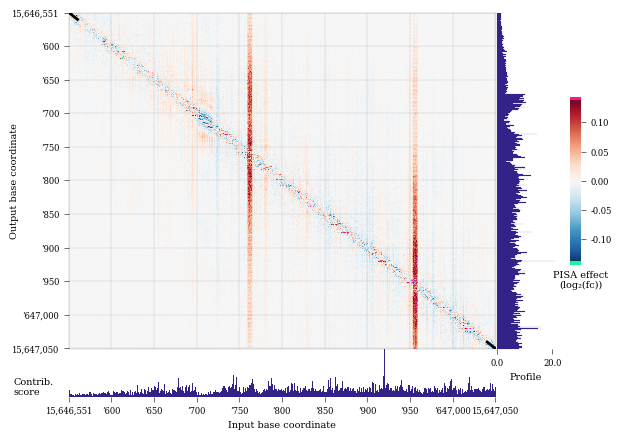

In [79]:
# Since it's just one job, I didn't bother with jobSpecs for that. I ran the slurm script.
import bpreveal.plotting as bprplots
def plotPisa():
    nameColors = dict()
    fig = plt.figure()
    cfgPos = {
        "pisa": {"h5-name": WORKING_DIRECTORY + "/shap/pisa.h5"},
        "coordinates": {
            "genome-fasta": GENOME_FASTA,
            "midpoint-offset": 800,
            "input-slice-width": 500,
            "output-slice-width": 500,
            "genome-window-start": 15646000,
            "genome-window-chrom": "chrX"},
        "predictions":{ "bigwig-name": WORKING_DIRECTORY + "/pred/residual.bw"},
        "importance": {"bigwig-name": WORKING_DIRECTORY + "/shap/joint_residual_profile.bw", "show-sequence": False},
        "annotations": {},#"bed-name": WORKING_DIRECTORY + "/scan/nanog_profile.bed",
                        #"name-colors": nameColors},
        "figure":{
            "left": 0.1, "bottom": 0.1, "width": 0.8, "height": 0.8,
            "color-span": 0.1, "miniature": False}
    }
    bprplots.plotPisa(cfgPos, fig)
plotPisa()